# Course 14: AI Research in 2026
## Session 2: Agents and long tasks: measuring time horizons

**Goal:** fit an agent's 50% and 80% time horizons from simulated task results, put bootstrap intervals on them, estimate a doubling time, and see how a capped task suite and scoring rules bias the estimates.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. The 2026 work behind this lab
**METR, "Time Horizon 1.1"** (29 January 2026) updated METR's measurement of how long a task (measured in human working time) AI agents can complete. The method comes from **Kwa et al. 2025, "Measuring AI Ability to Complete Long Tasks"** (arXiv 2503.14499): give agents many tasks whose human completion time is known, fit a logistic curve of success against log task length, and read off the length at which the agent succeeds 50% of the time. METR's **Frontier Risk Report** (May 2026) adds that the strongest models it assessed now reach the range where its task suite cannot measure horizons reliably.

This lab is a toy illustration, not a reproduction. The agents and tasks are simulated, so we know the true horizons and can check the method. METR's real analysis makes more choices (how tasks are weighted, how human times are measured or estimated, how the bootstrap is done) than this toy does.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
rng = np.random.default_rng(0)

### 2. A simulated task suite
228 tasks, with human completion times spread evenly on a log scale from 2 seconds to 16 hours. Each agent runs each task 4 times. A simulated agent with true 50% horizon $h$ succeeds on a task of length $t$ with probability $\sigma(\beta(\log_2 h - \log_2 t))$, where $\sigma$ is the logistic function and $\beta = 0.8$ sets how fast success falls as tasks get longer.

In [2]:
n_tasks, runs_per_task, SLOPE = 228, 4, 0.8
log2_min = rng.uniform(np.log2(2 / 60), np.log2(16 * 60), n_tasks)     # task length in log2(minutes)
minutes = 2.0 ** log2_min

def success_prob(h50_min, x=log2_min, slope=SLOPE):
    return 1 / (1 + np.exp(-slope * (np.log2(h50_min) - x)))

def run_agent(h50_min, x=log2_min, runs=runs_per_task):
    return rng.binomial(runs, success_prob(h50_min, x))                 # number of successes per task

print(f"tasks: {n_tasks} | shortest {60 * minutes.min():.0f} s | longest {minutes.max() / 60:.1f} h | "
      f"8 hours or longer: {np.sum(minutes >= 480)} | runs per task: {runs_per_task}")

tasks: 228 | shortest 2 s | longest 15.5 h | 8 hours or longer: 21 | runs per task: 4


### 3. Fit the logistic curve and read off the horizons
For each agent, fit $p(t) = \sigma(a + b \log_2 t)$ by maximum likelihood (Newton's method, with a tiny ridge penalty so the fit stays finite when an agent succeeds at everything). The 50% horizon is the $t$ where $p = 0.5$, that is $\log_2 t = -a/b$. The 80% horizon is where $p = 0.8$.

agent A: 50% horizon true    15 min, fitted   14.2 min | 80% horizon true   4.5 min, fitted    4.1 min
agent B: 50% horizon true   120 min, fitted  132.2 min | 80% horizon true  36.1 min, fitted   46.7 min
agent C: 50% horizon true   600 min, fitted  440.8 min | 80% horizon true 180.5 min, fitted  149.0 min


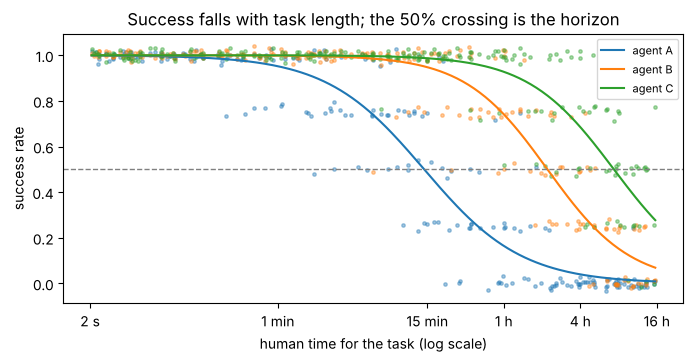

In [3]:
def fit_logistic(x, succ, runs, weights=None, ridge=1e-3, iters=40):
    # maximise sum_i w_i [s_i log p_i + (r_i - s_i) log(1 - p_i)] with p_i = sigmoid(a + b x_i), for many weight vectors at once
    W = np.ones((1, len(x))) if weights is None else np.atleast_2d(weights).astype(float)
    X = np.stack([np.ones_like(x), x], 1)
    theta = np.zeros((W.shape[0], 2))
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(theta @ X.T, -30, 30)))
        grad = (W * (succ - runs * p)) @ X - ridge * theta
        hess = np.einsum("bn,ni,nj->bij", W * runs * p * (1 - p), X, X) + ridge * np.eye(2)
        theta = theta + np.linalg.solve(hess, grad[..., None])[..., 0]
    return theta

def horizon(theta, q=0.5):
    a, b = theta[..., 0], theta[..., 1]
    with np.errstate(over="ignore", divide="ignore"):
        h = 2.0 ** ((np.log(q / (1 - q)) - a) / b)         # task length (minutes) with success probability q
    return np.where(b < -1e-3, h, np.inf)                  # if success does not fall with length, the horizon is not identified

true_h50 = {"agent A": 15, "agent B": 120, "agent C": 600}  # minutes
fits = {}
for name, h in true_h50.items():
    s = run_agent(h)
    theta = fit_logistic(log2_min, s, runs_per_task)[0]
    fits[name] = (s, theta)
    true_h80 = 2.0 ** (np.log2(h) - np.log(4) / SLOPE)
    print(f"{name}: 50% horizon true {h:5.0f} min, fitted {horizon(theta):6.1f} min | "
          f"80% horizon true {true_h80:5.1f} min, fitted {horizon(theta, 0.8):6.1f} min")

fig, ax = plt.subplots(figsize=(8, 3.5))
grid = np.linspace(log2_min.min(), log2_min.max(), 200)
for (name, (s, theta)), colour in zip(fits.items(), ["C0", "C1", "C2"]):
    ax.scatter(log2_min, s / runs_per_task + rng.normal(0, 0.015, n_tasks), s=6, alpha=0.4, color=colour)
    ax.plot(grid, 1 / (1 + np.exp(-(theta[0] + theta[1] * grid))), color=colour, label=name)
ax.axhline(0.5, ls="--", c="gray", lw=1)
ax.set_xticks(np.log2([1 / 30, 1, 15, 60, 240, 960]), ["2 s", "1 min", "15 min", "1 h", "4 h", "16 h"])
ax.set_xlabel("human time for the task (log scale)")
ax.set_ylabel("success rate")
ax.set_title("Success falls with task length; the 50% crossing is the horizon")
ax.legend(fontsize=8)
plt.show()

### 4. How sure are we? A bootstrap over tasks
Resample the 228 tasks with replacement 1,000 times, refit each time, and take the 2.5th and 97.5th percentiles of the horizons.

In [4]:
n_boot = 1000
boot_w = rng.multinomial(n_tasks, np.ones(n_tasks) / n_tasks, size=n_boot)    # how often each task appears in each resample
for name, (s, theta) in fits.items():
    tb = fit_logistic(log2_min, s, runs_per_task, weights=boot_w)
    lo50, hi50 = np.percentile(horizon(tb), [2.5, 97.5])
    lo80, hi80 = np.percentile(horizon(tb, 0.8), [2.5, 97.5])
    print(f"{name}: 50% horizon {horizon(theta):6.1f} min (95% CI {lo50:6.1f} to {hi50:6.1f}) | "
          f"80% horizon {horizon(theta, 0.8):5.1f} min (95% CI {lo80:5.1f} to {hi80:5.1f})")

agent A: 50% horizon   14.2 min (95% CI   11.6 to   17.4) | 80% horizon   4.1 min (95% CI   3.3 to   5.4)
agent B: 50% horizon  132.2 min (95% CI  112.5 to  153.9) | 80% horizon  46.7 min (95% CI  35.9 to  60.6)


agent C: 50% horizon  440.8 min (95% CI  364.0 to  544.1) | 80% horizon 149.0 min (95% CI 116.7 to 191.0)


If one interval misses the true value, is that a bug or bad luck? A simulation can tell: repeat the whole experiment for agent C 100 times and count how often the 95% interval contains the true 600 minutes. It should be close to 95%.

In [5]:
covered = []
for _ in range(100):
    s = run_agent(600)
    wb = rng.multinomial(n_tasks, np.ones(n_tasks) / n_tasks, size=300)
    lo, hi = np.percentile(horizon(fit_logistic(log2_min, s, runs_per_task, weights=wb)), [2.5, 97.5])
    covered.append(lo <= 600 <= hi)
print(f"agent C, 100 repeated experiments: the 95% interval contained the true horizon in {np.mean(covered):.2f} of them")

agent C, 100 repeated experiments: the 95% interval contained the true horizon in 0.91 of them


### 5. A trend over model releases, and its doubling time
Simulate 20 model releases between 2019 and late 2025 (half of them from 2024 on, as releases have become more frequent) whose true horizons double every 196 days, the figure METR reports for its whole 2019–2025 trend, plus random model-to-model scatter. Measure each one on the suite, fit a straight line to $\log_2$(horizon) against release date, and convert the slope to a doubling time. Then refit using only the models released from 2024 on.

all 20 models: doubling time 198 days (bootstrap 95% CI 188 to 212); true value 196
the 10 models from 2024 on: doubling time 182 days (bootstrap 95% CI 140 to 265); true value 196


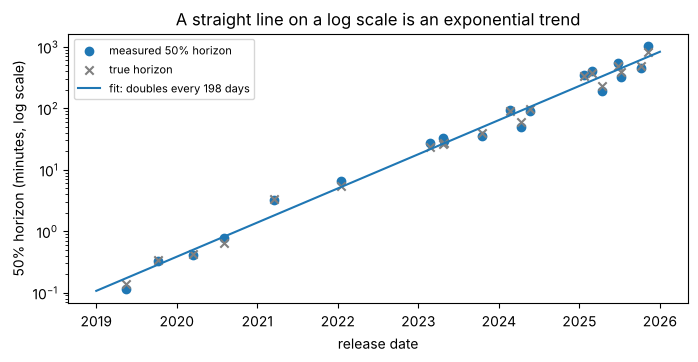

In [6]:
dates = np.sort(np.concatenate([rng.uniform(2019.0, 2024.0, 10), rng.uniform(2024.0, 2025.9, 10)]))
true_h = 0.1 * 2.0 ** ((dates - 2019.0) * 365.25 / 196) * 2.0 ** rng.normal(0, 0.5, len(dates))   # minutes
est_h = np.array([horizon(fit_logistic(log2_min, run_agent(h), runs_per_task)[0]) for h in true_h])

def doubling_days(d, h, n_boot=2000):
    slope = np.polyfit(d, np.log2(h), 1)[0]
    boots = []
    for _ in range(n_boot):
        i = rng.integers(0, len(d), len(d))
        if len(np.unique(i)) >= 3:
            boots.append(365.25 / np.polyfit(d[i], np.log2(h[i]), 1)[0])
    return 365.25 / slope, np.percentile(boots, [2.5, 97.5])

dd, (lo, hi) = doubling_days(dates, est_h)
print(f"all {len(dates)} models: doubling time {dd:.0f} days (bootstrap 95% CI {lo:.0f} to {hi:.0f}); true value 196")
recent = dates >= 2024
dd_r, (lo_r, hi_r) = doubling_days(dates[recent], est_h[recent])
print(f"the {recent.sum()} models from 2024 on: doubling time {dd_r:.0f} days (bootstrap 95% CI {lo_r:.0f} to {hi_r:.0f}); true value 196")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(dates, est_h, label="measured 50% horizon")
ax.scatter(dates, true_h, marker="x", c="gray", label="true horizon")
dgrid = np.linspace(2019, 2026, 50)
a0, b0 = np.polyfit(dates, np.log2(est_h), 1)
ax.plot(dgrid, 2.0 ** (a0 * dgrid + b0), label=f"fit: doubles every {dd:.0f} days")
ax.set_yscale("log")
ax.set_xlabel("release date")
ax.set_ylabel("50% horizon (minutes, log scale)")
ax.set_title("A straight line on a log scale is an exponential trend")
ax.legend(fontsize=8)
plt.show()

### 6. A capped task suite
No task in the suite is longer than 16 hours. What happens to agents whose true horizon is near or above that? Compare the same agents on the full suite and on a suite with no task longer than 2 hours.

true   1 h | full suite (max 16 h)  | success rate 0.68 | estimate      1.0 h | 95% CI      0.8 h to      1.2 h | CI contains truth: yes
true   1 h | short suite (max 2 h)  | success rate 0.87 | estimate      0.8 h | 95% CI      0.7 h to      1.1 h | CI contains truth: yes
true   4 h | full suite (max 16 h)  | success rate 0.82 | estimate      4.3 h | 95% CI      3.5 h to      5.2 h | CI contains truth: yes


true   4 h | short suite (max 2 h)  | success rate 0.96 | estimate      3.8 h | 95% CI      2.3 h to      9.7 h | CI contains truth: yes
true  16 h | full suite (max 16 h)  | success rate 0.93 | estimate     20.6 h | 95% CI     14.0 h to     34.7 h | CI contains truth: yes
true  16 h | short suite (max 2 h)  | success rate 0.99 | estimate     15.1 h | 95% CI      3.1 h to   no bound | CI contains truth: yes


true  32 h | full suite (max 16 h)  | success rate 0.97 | estimate     31.5 h | 95% CI     20.2 h to     64.9 h | CI contains truth: yes
true  32 h | short suite (max 2 h)  | success rate 1.00 | estimate    214.6 h | 95% CI      3.1 h to   no bound | CI contains truth: yes


true  64 h | full suite (max 16 h)  | success rate 0.97 | estimate     99.8 h | 95% CI     21.8 h to   1775.8 h | CI contains truth: yes
true  64 h | short suite (max 2 h)  | success rate 1.00 | not identifiable: success does not fall with task length


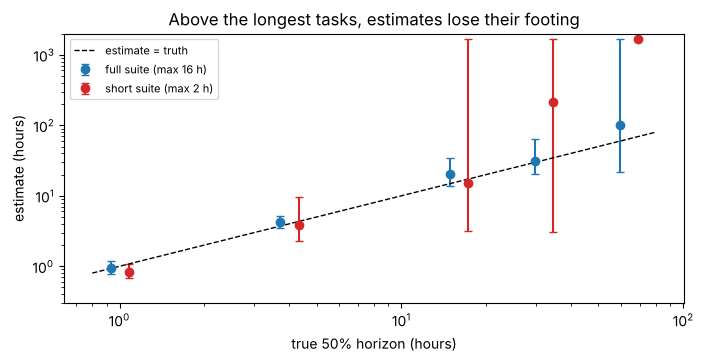

In [7]:
short = minutes <= 120
suites = {"full suite (max 16 h)": np.ones(n_tasks, bool), "short suite (max 2 h)": short}
results = []
for h in [60, 240, 960, 1920, 3840]:
    for suite, mask in suites.items():
        s = run_agent(h, x=log2_min[mask])
        est = horizon(fit_logistic(log2_min[mask], s, runs_per_task)[0])
        wb = rng.multinomial(mask.sum(), np.ones(mask.sum()) / mask.sum(), size=500)
        hb = horizon(fit_logistic(log2_min[mask], s, runs_per_task, weights=wb))
        lo, hi = np.percentile(hb, 2.5, method="lower"), np.percentile(hb, 97.5, method="higher")   # no interpolation, so infinities are safe
        results.append((h, suite, est, lo, hi))
        rate = s.sum() / (runs_per_task * mask.sum())
        fmt = lambda v: f"{v / 60:8.1f} h" if np.isfinite(v) and v < 6e5 else "  no bound"
        if not np.isfinite(est):
            print(f"true {h / 60:3.0f} h | {suite:22s} | success rate {rate:.2f} | not identifiable: success does not fall with task length")
            continue
        inside = "yes" if lo <= h <= hi else "NO"
        print(f"true {h / 60:3.0f} h | {suite:22s} | success rate {rate:.2f} | estimate {fmt(est)} | "
              f"95% CI {fmt(lo)} to {fmt(hi)} | CI contains truth: {inside}")

fig, ax = plt.subplots(figsize=(8, 3.5))
for k, (suite, colour) in enumerate(zip(suites, ["C0", "C3"])):
    rows = [r for r in results if r[1] == suite]
    x = np.array([r[0] for r in rows]) / 60 * (1.08 if k else 0.93)
    est = np.array([min(r[2], 1e5) for r in rows]) / 60
    lo = np.array([max(min(r[3], 1e5), 1) for r in rows]) / 60
    hi = np.array([min(r[4], 1e5) for r in rows]) / 60
    ax.errorbar(x, est, yerr=[np.maximum(est - lo, 0), np.maximum(hi - est, 0)], fmt="o", color=colour, capsize=3, label=suite)
ax.plot([0.8, 80], [0.8, 80], "k--", lw=1, label="estimate = truth")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.3, 2000)
ax.set_xlabel("true 50% horizon (hours)")
ax.set_ylabel("estimate (hours)")
ax.set_title("Above the longest tasks, estimates lose their footing")
ax.legend(fontsize=8)
plt.show()

### 7. Scoring choices: what counts as a success?
Some agent runs "succeed" by cheating, for example by editing the tests that check them. METR counts a cheating attempt it detects as a failure. Suppose an agent with a true 4-hour horizon cheats on 30% of the runs it would otherwise fail on tasks longer than 1 hour. Fit the horizon both ways.

In [8]:
h = 240
honest = run_agent(h)
cheats = rng.binomial(runs_per_task - honest, 0.3 * (minutes > 60))
wb = rng.multinomial(n_tasks, np.ones(n_tasks) / n_tasks, size=1000)
print(f"runs that cheated: {cheats.sum()} of {runs_per_task * n_tasks}")
for rule, s in [("cheats counted as failures ", honest), ("cheats counted as successes", honest + cheats)]:
    est = horizon(fit_logistic(log2_min, s, runs_per_task)[0])
    lo, hi = np.percentile(horizon(fit_logistic(log2_min, s, runs_per_task, weights=wb)), [2.5, 97.5])
    print(f"50% horizon, {rule}: {est / 60:4.1f} h (95% CI {lo / 60:4.1f} to {hi / 60:4.1f} h); true 4.0 h")

runs that cheated: 49 of 912
50% horizon, cheats counted as failures :  3.9 h (95% CI  3.1 to  4.9 h); true 4.0 h


50% horizon, cheats counted as successes:  8.8 h (95% CI  6.5 to 12.5 h); true 4.0 h


### 8. METR's public data (NOT RUN here)
METR publishes its run data and analysis code. The cell below shows how to fit the horizons yourself; check the file layout and column names in the repository's README first.

In [ ]:
# NOT RUN: needs internet access and git (clones https://github.com/METR/eval-analysis-public)
import subprocess
import pandas as pd
subprocess.run(["git", "clone", "--depth", "1", "https://github.com/METR/eval-analysis-public"], check=True)
runs = pd.read_json("eval-analysis-public/reports/time-horizon-1-1/data/raw/runs.jsonl", lines=True)   # path from the README; check it
print(runs.columns.tolist())                       # look at the real column names first
MODEL, MINUTES, SCORE = "alias", "human_minutes", "score_binarized"    # guesses: replace with the names printed above
for model, df in runs.groupby(MODEL):
    x = np.log2(df[MINUTES].to_numpy(dtype=float))
    s = df[SCORE].to_numpy(dtype=float)
    theta = fit_logistic(x, s, np.ones_like(s))[0]
    print(f"{model:40s} 50% horizon {horizon(theta):8.1f} min")
# METR's published numbers use more careful choices (task weights, bootstrap design), so expect yours to differ somewhat.

### 9. Your turn

In [9]:
# TODO: how much do repeated runs help? Re-run sections 3 and 4 for agent B with runs_per_task = 1 and = 16
# (pass runs=... to run_agent and the same number to fit_logistic) and compare the width of the 95% interval.
def interval_width(runs):
    return None                                    # return hi - lo of the 50% horizon interval, in minutes

widths = {r: interval_width(r) for r in [1, 4, 16]}
print(widths if all(w is not None for w in widths.values()) else "not done yet")

not done yet


In [10]:
# TODO: estimate the doubling time of the 80% horizon for the 14 simulated models in section 5.
# Is it the same as for the 50% horizon in this toy? Why? (Hint: look at how success_prob uses SLOPE.)
doubling_80 = None
print(doubling_80 if doubling_80 is not None else "not done yet")

not done yet


### What to notice
- The fitted 50% horizons were 14.2, 132.2 and 440.8 minutes for true values of 15, 120 and 600. Agent C's 95% interval (364.0 to 544.1 minutes) missed the truth. Repeating agent C's experiment 100 times, the interval contained the truth in 91 of them, a little below the 95% target. So the miss was mostly bad luck, and bootstrap intervals can be slightly too narrow.
- The 80% horizons were roughly three times shorter than the 50% horizons (4.1 against 14.2 minutes, 46.7 against 132.2, 149.0 against 440.8). That ratio comes from the slope we chose. Kwa et al. report that 80% horizons of real agents are about five times shorter, so always ask which success level a horizon refers to.
- From all 20 simulated releases the doubling time came out at 198 days (95% CI 188 to 212) for a true value of 196. From the 10 releases since 2024 it was 182 days (140 to 265): fewer points give a much wider interval, even though the true trend never changed.
- On the full suite the estimates were fine up to a 32-hour agent (31.5 h, interval 20.2 to 64.9 h), but a 64-hour agent got an interval from 21.8 to 1,775.8 hours. On a suite with no task longer than 2 hours, the 16-hour and 32-hour agents got intervals with no upper bound (the 32-hour agent's point estimate was 214.6 h), and the 64-hour agent, which succeeded on every run, could not be estimated at all. When almost every run succeeds, the data only say "longer than the longest tasks".
- Counting the 49 cheating runs (5% of 912) as successes moved the estimate from 3.9 h to 8.8 h, far outside the honest interval of 3.1 to 4.9 h. How a few runs on long tasks are scored can decide the headline number.